# RECIPE GEOFISIKA: QA/QC DATA VES SCHLUMBERGER DAN PERHITUNGAN RESISTIVITAS SEMU

**Nama:** Aleksander  
**NIM:** H061251003  
**Mata Kuliah:** Kecerdasan Artifisial untuk Geofisika  
**Kelas:** [A]  
**Departemen Geofisika, Universitas Hasanuddin**

---

## Identitas Recipe

| Item | Isi |
|---|---|
| **Recipe ID** | R-GEO-001 |
| **Prompt ID** | P-GEO-001 |
| **Bidang** | Geofisika eksplorasi (metode geolistrik) |
| **Satu outcome utama** | Laporan QA/QC data *Vertical Electrical Sounding* (VES) konfigurasi Schlumberger: ρa dihitung, data mencurigakan **ditandai** beserta alasannya |
| **Bukan outcome recipe ini** | Inversi 1D/2D, interpretasi litologi, atau analisis ekuivalensi (itu recipe lain) |
| **Status evidence** | **Executed** pada **data sintetis** (lihat bagian *Run Record*). Bukan hasil pengukuran lapangan |
| **Artifact yang dihasilkan** | `data_ves_sintetis.csv`, `resistivitas_semu_qc.csv`, `ringkasan_qc.md`, `run_record_r-geo-001.json`, `qc_ves.png` |

> **Petunjuk notebook:** sel *Markdown* berisi penjelasan, sel *Code* dijalankan dengan tombol **Run**. Jalankan dari atas ke bawah. Hanya memakai `numpy`, `pandas`, dan `matplotlib` (sudah ada di Google Colab).

## 1. Problem — Permasalahan

Sebelum data sounding diinversikan, kita perlu tahu apakah data itu layak dipakai. Satu titik buruk (misalnya ρa negatif, arus terlalu kecil, atau ΔV tenggelam dalam noise) tidak dianggap salah oleh program inversi; program akan berusaha mencocokkannya sehingga muncul lapisan yang sebenarnya tidak ada.

Recipe ini menjawab satu pertanyaan sempit: **apakah tabel data VES Schlumberger ini layak menjadi input inversi, dan titik mana yang perlu diperiksa?**

Tujuan yang dapat diperiksa:
1. Memeriksa skema tabel (kolom wajib, tipe numerik, nilai kosong, geometri elektroda).
2. Menghitung faktor geometri $K$ dan resistivitas semu $\rho_a$ pada **kolom baru** tanpa mengubah data mentah.
3. **Menandai** (bukan menghapus) titik mencurigakan beserta alasan dan ambangnya.
4. Menjalankan verifikasi, lalu menyimpan laporan dan *run record*.

**Batasan keputusan:** hasil recipe ini adalah daftar *flag*, bukan keputusan akhir. Titik ter-flag perlu dicocokkan dengan catatan lapangan sebelum dibuang.

## 2. Minimal Theory — Teori Singkat

Resistivitas semu dihitung dari arus $I$, beda potensial $\Delta V$, dan faktor geometri $K$:

$$
\rho_a = K\,\frac{\Delta V}{I}
$$

Untuk konfigurasi Schlumberger dengan setengah panjang bentangan arus $s = AB/2$ dan jarak elektroda potensial $MN$ (dengan $MN \ll AB$):

$$
K = \frac{\pi\left(s^{2} - (MN/2)^{2}\right)}{MN}
$$

Satuan: $K$ dalam m, $I$ dalam A, $\Delta V$ dalam V, sehingga $\rho_a$ dalam $\Omega\cdot$m. Data lapangan biasanya dicatat dalam **mA** dan **mV**, jadi konversi satuan harus eksplisit.

Aturan QC yang dipakai (ambang dapat diubah sesuai alat dan lokasi):

| Aturan flag | Ambang | Alasan fisis |
|---|---|---|
| ρa tidak positif | ρa ≤ 0 | ρa fisis selalu positif; tanda ΔV terbalik atau noise |
| Arus terlalu kecil | I < 10 mA | sinyal rendah terhadap noise |
| ΔV di bawah kepekaan alat | \|ΔV\| < 1 mV | pembacaan tidak andal |
| Selisih *overlap* antar-MN pada AB/2 yang sama | > 10 % | kontak elektroda buruk atau efek lateral |

**Catatan:** ini QC pembelajaran sederhana, bukan prosedur baku survei. Ambang adalah asumsi yang ditulis terbuka agar keputusan dapat ditelusuri.

## 3. Input dan Constraint Contract

| Aspek | Ketentuan |
|---|---|
| Input | Tabel VES dengan kolom `AB/2 (m)`, `MN (m)`, `I (mA)`, `dV (mV)` |
| Sumber data di notebook ini | **Sintetis** (dibangkitkan kode). Bila memakai data asli, set `USE_SIMULATED_DATA = False` dan sediakan `data_ves.csv` |
| Satuan | AB/2 dan MN dalam meter; I dalam mA; ΔV dalam mV |
| Boleh diubah | Hanya file keluaran baru. **Data mentah tidak boleh ditimpa** (dibuktikan dengan hash SHA-256 sebelum dan sesudah) |
| Dilarang | Menghapus baris diam-diam, mengimputasi nilai, atau mengisi nilai yang hilang |
| Jaringan | Tidak diperlukan |
| Keluaran | Lihat tabel *Identitas Recipe* |

## 4. Prompt — Instruksi untuk AI (P-GEO-001)

Prompt disusun dengan struktur **R–T–C–I–K–O–Q–V** dari Tugas 1. Bagian dalam `[...]` diisi sebelum dipakai.

> **R (Role):** Kamu adalah asisten pengolah data geolistrik yang bekerja dengan teliti dan tidak mengarang data.
>
> **T (Task):** Baca `[NAMA_FILE_DATA]`, hitung faktor geometri K dan resistivitas semu ρa untuk konfigurasi Schlumberger, tandai titik mencurigakan beserta alasan, lalu buat laporan QA/QC.
>
> **C (Context):** Hasilnya dipakai untuk memutuskan data mana yang layak masuk inversi 1D. Ini bukan interpretasi geologi.
>
> **I (Input):** Kolom `AB/2 (m)`, `MN (m)`, `I (mA)`, `dV (mV)`. Konversi mA→A dan mV→V pada kolom baru. Jangan memakai data lain.
>
> **K (Constraints):** Jangan mengubah atau menghapus data mentah. Tandai, jangan buang. Tulis ambang tiap aturan: ρa ≤ 0; I < `[I_MIN]` mA; |ΔV| < `[DV_MIN]` mV; selisih overlap antar-MN > `[TOL]` %. Jangan mengarang nilai; bila kolom ambigu, minta klarifikasi.
>
> **O (Output):** `resistivitas_semu_qc.csv` (semua baris asli + K, ρa, flag, alasan), `ringkasan_qc.md`, gambar ρa terhadap AB/2 (log-log), dan `run_record_r-geo-001.json`.
>
> **Q (Quality criteria):** jumlah baris keluaran = jumlah baris masukan; setiap flag punya alasan; tidak ada ρa kosong atau tak hingga; satu titik dihitung ulang manual cocok dengan program (selisih relatif < 1e-6).
>
> **V (Verification):** Jalankan semua pemeriksaan sebelum membuat gambar akhir. Bila ada yang gagal, hentikan dan laporkan penyebabnya. Jika data sintetis dipakai, nyatakan jelas bahwa hasilnya bukan data lapangan.

## 5. Code — Persiapan dan Pengaturan

In [1]:
import sys, json, hashlib, platform, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

RECIPE_ID, PROMPT_ID = "R-GEO-001", "P-GEO-001"

# ---- Pengaturan (ubah di sini) ----
USE_SIMULATED_DATA = True            # False -> baca data_ves.csv milik sendiri
RAW_FILE = Path("data_ves_sintetis.csv" if USE_SIMULATED_DATA else "data_ves.csv")
I_MIN_mA, DV_MIN_mV, TOL_OVERLAP = 10.0, 1.0, 0.10   # ambang QC (lihat Minimal Theory)

# ---- Pencatat pemeriksaan (verifikasi) ----
CHECKS = []
def check(nama, kondisi, detail=""):
    CHECKS.append({"pemeriksaan": nama, "lulus": bool(kondisi), "detail": detail})
    print(("[LULUS] " if kondisi else "[GAGAL] ") + nama + (f"  ->  {detail}" if detail else ""))

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

print("Python", sys.version.split()[0], "| numpy", np.__version__, "| pandas", pd.__version__, "| matplotlib", matplotlib.__version__)

Python 3.12.3 | numpy 2.4.4 | pandas 3.0.2 | matplotlib 3.10.8


## 6. Code — Sumber Data

- `USE_SIMULATED_DATA = True`: membangkitkan data **sintetis** dengan beberapa cacat yang **disengaja** agar prosedur QC dapat diuji. Kurva ρa dibuat dari interpolasi sederhana, bukan dari model bumi tertentu.
- `USE_SIMULATED_DATA = False`: tidak membangkitkan apa pun; recipe langsung membaca `data_ves.csv`.

Cacat yang disengaja: tanda ΔV terbalik, arus terlalu kecil, ΔV terlalu kecil, dan selisih *overlap* antar-MN.

In [2]:
CACAT_DISENGAJA = []     # hanya terisi pada data sintetis

if USE_SIMULATED_DATA:
    rng = np.random.default_rng(2026)                      # seed tetap agar dapat diulang
    ab2 = np.array([1.5, 2, 3, 4, 6, 8, 10, 15, 20, 30, 40, 60, 80, 100, 150, 200, 300], float)
    mn_pakai = lambda s: 0.5 if s <= 10 else (2.0 if s <= 40 else 10.0)
    arus     = lambda s: 100.0 if s <= 10 else (200.0 if s <= 40 else 500.0)   # mA

    rows = []
    for s in ab2:
        daftar_mn = [mn_pakai(s)]
        if s == 10.0: daftar_mn = [0.5, 2.0]               # titik pergantian MN: ukur dua MN (overlap)
        if s == 40.0: daftar_mn = [2.0, 10.0]
        for mn in daftar_mn:
            rows.append({"AB/2 (m)": s, "MN (m)": mn, "I (mA)": arus(s)})
    raw = pd.DataFrame(rows)

    # kurva rho_a "ilustratif" (interpolasi log-log), BUKAN model bumi
    simpul_s, simpul_r = [1.5, 10, 40, 100, 300], [110, 30, 60, 250, 420]
    rho_true = np.exp(np.interp(np.log(raw["AB/2 (m)"]), np.log(simpul_s), np.log(simpul_r)))
    K_true = np.pi*(raw["AB/2 (m)"]**2 - (raw["MN (m)"]/2)**2)/raw["MN (m)"]
    raw["dV (mV)"] = rho_true*(raw["I (mA)"]/1000)/K_true*1000*(1 + rng.normal(0, 0.02, len(raw)))  # noise 2 %

    def idx(s, mn): return int(raw.index[(raw["AB/2 (m)"] == s) & (raw["MN (m)"] == mn)][0])
    i1, i2, i3, i4 = idx(4.0, 0.5), idx(100.0, 10.0), idx(300.0, 10.0), idx(40.0, 10.0)
    raw.loc[i1, "dV (mV)"] *= -0.2                         # tanda dV terbalik
    raw.loc[i2, "I (mA)"] = 6.0                            # arus terlalu kecil
    raw.loc[i2, "dV (mV)"] = rho_true[i2]*0.006/K_true[i2]*1000
    raw.loc[i3, "I (mA)"] = 20.0                           # dV akan sangat kecil
    raw.loc[i3, "dV (mV)"] = rho_true[i3]*0.020/K_true[i3]*1000
    raw.loc[i4, "dV (mV)"] *= 1.18                         # overlap antar-MN tidak konsisten
    CACAT_DISENGAJA = sorted([i1, i2, i3, i4, idx(40.0, 2.0)])   # baris 40 m/MN 2 ikut ter-flag lewat aturan overlap
    raw.insert(0, "No", np.arange(1, len(raw) + 1))
    raw.to_csv(RAW_FILE, index=False)
    print(f"DATA SINTETIS dibuat: {RAW_FILE} ({len(raw)} baris). Bukan hasil pengukuran lapangan.")

HASH_AWAL = sha256(RAW_FILE)           # bukti data mentah tidak diubah
df = pd.read_csv(RAW_FILE)
display(df.round(3).head(8))

DATA SINTETIS dibuat: data_ves_sintetis.csv (19 baris). Bukan hasil pengukuran lapangan.


   No  AB/2 (m)  MN (m)  I (mA)  dV (mV)
0   1       1.5     0.5   100.0  787.627
1   2       2.0     0.5   100.0  366.868
2   3       3.0     0.5   100.0  117.230
3   4       4.0     0.5   100.0  -11.536
4   5       6.0     0.5   100.0   19.092
5   6       8.0     0.5   100.0    8.650
6   7      10.0     0.5   100.0    4.748
7   8      10.0     2.0   100.0   19.409

## 7. Code — Pemeriksaan Skema

Bagian ini memeriksa kolom wajib, tipe numerik, nilai kosong, dan geometri elektroda. Bila gagal, analisis dihentikan agar masalah data tidak tersembunyi.

In [3]:
wajib = ["AB/2 (m)", "MN (m)", "I (mA)", "dV (mV)"]
hilang = [c for c in wajib if c not in df.columns]
if hilang:
    raise ValueError(f"Kolom wajib tidak ditemukan: {hilang}")
if "No" not in df.columns:
    df.insert(0, "No", np.arange(1, len(df) + 1))

num = df[wajib].apply(pd.to_numeric, errors="coerce")
print("Jumlah baris, kolom :", df.shape)
print("Nilai kosong/non-numerik per kolom:\n", num.isna().sum().to_string())
if num.isna().any().any():
    raise ValueError("Ada nilai kosong atau non-numerik. Periksa data mentah (tidak diimputasi oleh recipe ini).")
if (num["MN (m)"] >= 2*num["AB/2 (m)"]).any() or (num["MN (m)"] <= 0).any():
    raise ValueError("Geometri tidak valid: MN harus > 0 dan lebih kecil dari AB.")
print("\nMaks MN/AB =", round(float((num['MN (m)']/(2*num['AB/2 (m)'])).max()), 3),
      "(pendekatan MN << AB makin baik bila rasio kecil)")
n_input = len(df)

Jumlah baris, kolom : (19, 5)
Nilai kosong/non-numerik per kolom:
 AB/2 (m)    0
MN (m)      0
I (mA)      0
dV (mV)     0

Maks MN/AB = 0.167 (pendekatan MN << AB makin baik bila rasio kecil)


## 8. Code — Hitung K dan ρa, Lalu Tandai Data Mencurigakan

Konversi satuan dilakukan pada **kolom baru**. Data ter-flag **tidak dihapus**; alasan dan ambangnya dicatat.

In [4]:
out = pd.DataFrame({
    "No": df["No"],
    "AB/2 (m)": df["AB/2 (m)"], "MN (m)": df["MN (m)"],
    "I (A)":  df["I (mA)"]/1000.0,          # kolom baru: mA -> A
    "dV (V)": df["dV (mV)"]/1000.0,         # kolom baru: mV -> V
})
out["K (m)"] = np.pi*(out["AB/2 (m)"]**2 - (out["MN (m)"]/2)**2)/out["MN (m)"]
out["rho_a (ohm.m)"] = out["K (m)"]*out["dV (V)"]/out["I (A)"]

alasan = [[] for _ in range(len(out))]
for i, r in out.iterrows():
    if r["rho_a (ohm.m)"] <= 0:               alasan[i].append("rho_a <= 0 (tanda dV terbalik / noise)")
    if r["I (A)"]*1000 < I_MIN_mA:            alasan[i].append(f"arus < {I_MIN_mA:g} mA")
    if abs(r["dV (V)"])*1000 < DV_MIN_mV:     alasan[i].append(f"|dV| < {DV_MIN_mV:g} mV (di bawah kepekaan alat)")
for s, g in out.groupby("AB/2 (m)"):
    if len(g) >= 2:
        pos = g.loc[g["rho_a (ohm.m)"] > 0, "rho_a (ohm.m)"]
        if len(pos) >= 2 and pos.max()/pos.min() - 1 > TOL_OVERLAP:
            for i in g.index:
                alasan[i].append(f"selisih overlap antar-MN {100*(pos.max()/pos.min()-1):.0f}% > {100*TOL_OVERLAP:.0f}%")

out["flag"] = [len(a) > 0 for a in alasan]
out["alasan_flag"] = ["; ".join(a) for a in alasan]

valid = out.loc[out["rho_a (ohm.m)"] > 0, "rho_a (ohm.m)"]
print(f"Jumlah data total          : {len(out)}")
print(f"Jumlah data ter-flag       : {int(out['flag'].sum())}")
print(f"Jumlah data tidak ter-flag : {int((~out['flag']).sum())}")
print(f"Rentang rho_a (hanya > 0)  : {valid.min():.1f} - {valid.max():.1f} ohm.m (median {valid.median():.1f})")
display(out.loc[out["flag"], ["No", "AB/2 (m)", "MN (m)", "I (A)", "dV (V)", "rho_a (ohm.m)", "alasan_flag"]].round(5))

Jumlah data total          : 19
Jumlah data ter-flag       : 5
Jumlah data tidak ter-flag : 14
Rentang rho_a (hanya > 0)  : 29.8 - 420.0 ohm.m (median 68.3)


    No  AB/2 (m)  MN (m)  I (A)   dV (V)  rho_a (ohm.m)                                         alasan_flag
3    4       4.0     0.5  0.100 -0.01154      -11.55171              rho_a <= 0 (tanda dV terbalik / noise)
11  12      40.0     2.0  0.200  0.00483       60.61765                  selisih overlap antar-MN 17% > 10%
12  13      40.0    10.0  0.200  0.02858       70.70919                  selisih overlap antar-MN 17% > 10%
15  16     100.0    10.0  0.006  0.00048      250.00000  arus < 10 mA; |dV| < 1 mV (di bawah kepekaan alat)
18  19     300.0    10.0  0.020  0.00030      420.00000                |dV| < 1 mV (di bawah kepekaan alat)

## 9. Code — Verifikasi (sebelum gambar dan penyimpanan)

Pemeriksaan ini mengikuti kriteria kualitas pada Prompt. Bila ada yang gagal, program berhenti.

In [5]:
# (1) hitung ulang satu titik secara manual, tanpa memakai kolom hasil di atas
r = df.iloc[7]
K_man = 3.141592653589793*(r["AB/2 (m)"]**2 - (r["MN (m)"]/2)**2)/r["MN (m)"]
rho_man = K_man*(r["dV (mV)"]/1000)/(r["I (mA)"]/1000)
sel = abs(rho_man - out.loc[7, "rho_a (ohm.m)"])/abs(rho_man)
check("Hitung ulang manual titik ke-8 cocok dengan program (selisih relatif < 1e-6)", sel < 1e-6, f"selisih = {sel:.2e}")

# (2) uji K pada kasus yang diketahui: AB/2 = 10 m, MN = 1 m -> K = pi*(100 - 0.25)/1
K_uji = np.pi*(10.0**2 - (1.0/2)**2)/1.0
check("K Schlumberger (AB/2=10 m, MN=1 m) = 313,37 m", abs(K_uji - 313.3739) < 1e-3, f"K = {K_uji:.4f} m")

# (3) jumlah baris dan flag
check("Jumlah baris keluaran = jumlah baris masukan", len(out) == n_input, f"{len(out)} = {n_input}")
check("Data ter-flag + tidak ter-flag = total", int(out["flag"].sum()) + int((~out["flag"]).sum()) == len(out))

# (4) nilai valid
check("Tidak ada rho_a kosong atau tak hingga", bool(np.isfinite(out["rho_a (ohm.m)"]).all()))
check("Setiap flag memiliki alasan", bool((out.loc[out["flag"], "alasan_flag"] != "").all()))

# (5) hanya untuk data sintetis: semua cacat yang disengaja harus tertangkap, dan tidak ada flag palsu
if USE_SIMULATED_DATA:
    ditandai = sorted(out.index[out["flag"]].tolist())
    check("Semua cacat yang disengaja tertangkap dan tidak ada flag palsu", ditandai == CACAT_DISENGAJA,
          f"ter-flag = {[i+1 for i in ditandai]}; seharusnya = {[i+1 for i in CACAT_DISENGAJA]} (nomor baris)")

# (6) data mentah tidak berubah
check("Data mentah tidak berubah (hash SHA-256 sama dengan sebelum analisis)", sha256(RAW_FILE) == HASH_AWAL)

if not all(c["lulus"] for c in CHECKS):
    raise RuntimeError("Ada pemeriksaan yang gagal: hentikan dan laporkan penyebabnya sebelum membuat gambar akhir.")
print("\nSemua pemeriksaan lulus.")

[LULUS] Hitung ulang manual titik ke-8 cocok dengan program (selisih relatif < 1e-6)  ->  selisih = 0.00e+00
[LULUS] K Schlumberger (AB/2=10 m, MN=1 m) = 313,37 m  ->  K = 313.3739 m
[LULUS] Jumlah baris keluaran = jumlah baris masukan  ->  19 = 19
[LULUS] Data ter-flag + tidak ter-flag = total
[LULUS] Tidak ada rho_a kosong atau tak hingga
[LULUS] Setiap flag memiliki alasan
[LULUS] Semua cacat yang disengaja tertangkap dan tidak ada flag palsu  ->  ter-flag = [4, 12, 13, 16, 19]; seharusnya = [4, 12, 13, 16, 19] (nomor baris)
[LULUS] Data mentah tidak berubah (hash SHA-256 sama dengan sebelum analisis)

Semua pemeriksaan lulus.


## 10. Code — Visualisasi

Titik baik dan titik ter-flag diberi tanda berbeda. ρa negatif tidak dapat digambar pada skala log, jadi dicatat dengan anotasi.

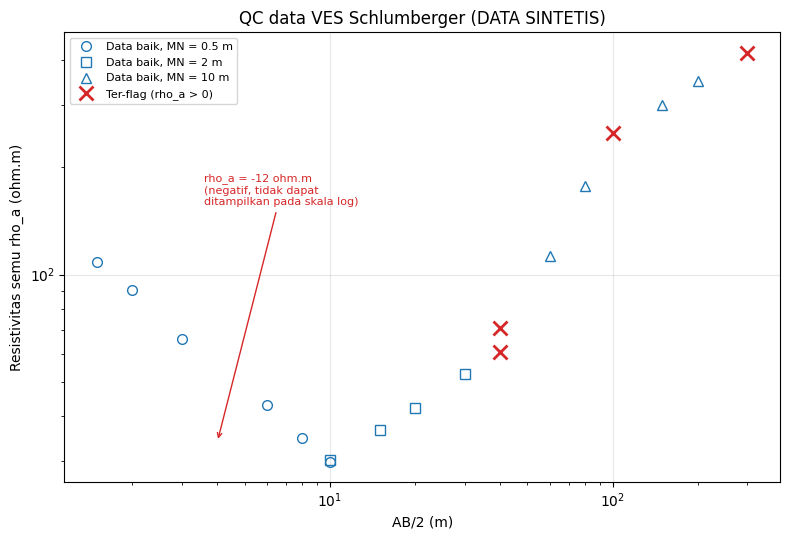

In [6]:
ok  = out[~out["flag"]]
bad = out[out["flag"] & (out["rho_a (ohm.m)"] > 0)]
neg = out[out["rho_a (ohm.m)"] <= 0]

fig, ax = plt.subplots(figsize=(8, 5.5))
for mn_val, mk in zip(sorted(out["MN (m)"].unique()), ["o", "s", "^"]):
    sub = ok[ok["MN (m)"] == mn_val]
    ax.loglog(sub["AB/2 (m)"], sub["rho_a (ohm.m)"], mk, ms=7, mfc="none", color="tab:blue", label=f"Data baik, MN = {mn_val:g} m")
ax.loglog(bad["AB/2 (m)"], bad["rho_a (ohm.m)"], "x", ms=10, mew=2, color="tab:red", label="Ter-flag (rho_a > 0)")
for _, rr in neg.iterrows():
    ax.annotate(f"rho_a = {rr['rho_a (ohm.m)']:.0f} ohm.m\n(negatif, tidak dapat\nditampilkan pada skala log)",
                xy=(rr["AB/2 (m)"], ax.get_ylim()[0]*1.3), xytext=(rr["AB/2 (m)"]*0.9, ax.get_ylim()[0]*6),
                fontsize=8, color="tab:red", arrowprops=dict(arrowstyle="->", color="tab:red"))
ax.set_xlabel("AB/2 (m)"); ax.set_ylabel("Resistivitas semu rho_a (ohm.m)")
ax.set_title(f"QC data VES Schlumberger ({'DATA SINTETIS' if USE_SIMULATED_DATA else 'data lapangan'})")
ax.grid(True, alpha=0.3); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("qc_ves.png", dpi=150); plt.show()

## 11. Code — Menyimpan Artifact dan Run Record

*Run record* menghubungkan hasil dengan bukti: versi paket, hash input dan output, daftar pemeriksaan, dan batas klaim. Status **Executed** hanya diberikan karena semua pemeriksaan di atas benar-benar lulus pada proses ini.

In [7]:
out.to_csv("resistivitas_semu_qc.csv", index=False)

n_flag = int(out["flag"].sum())
laporan = [
    f"# Laporan QA/QC VES Schlumberger ({RECIPE_ID})",
    "",
    f"- Sumber data : `{RAW_FILE}` ({'SINTETIS, bukan data lapangan' if USE_SIMULATED_DATA else 'data pengukuran'})",
    f"- Jumlah baris: {len(out)}; ter-flag: {n_flag}; tidak ter-flag: {len(out) - n_flag}",
    f"- Rentang rho_a (hanya > 0): {valid.min():.1f} - {valid.max():.1f} ohm.m",
    f"- Ambang: I < {I_MIN_mA:g} mA; |dV| < {DV_MIN_mV:g} mV; overlap > {100*TOL_OVERLAP:.0f}%; rho_a <= 0",
    "",
    "## Titik ter-flag",
    "",
    "| No | AB/2 (m) | MN (m) | rho_a (ohm.m) | Alasan |",
    "|---|---|---|---|---|",
] + [f"| {int(r['No'])} | {r['AB/2 (m)']:g} | {r['MN (m)']:g} | {r['rho_a (ohm.m)']:.1f} | {r['alasan_flag']} |"
     for _, r in out[out["flag"]].iterrows()] + [
    "",
    "Catatan: titik ter-flag ditandai, bukan dihapus. Keputusan membuang atau mempertahankan harus mempertimbangkan catatan lapangan.",
]
Path("ringkasan_qc.md").write_text("\n".join(laporan), encoding="utf-8")

record = {
    "recipe_id": RECIPE_ID, "prompt_id": PROMPT_ID,
    "status": "Executed" + (" (data sintetis)" if USE_SIMULATED_DATA else ""),
    "waktu_eksekusi": datetime.datetime.now().isoformat(timespec="seconds"),
    "lingkungan": {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                   "matplotlib": matplotlib.__version__, "platform": platform.platform()},
    "input": {"file": str(RAW_FILE), "sha256": HASH_AWAL, "baris": int(n_input)},
    "ambang": {"I_min_mA": I_MIN_mA, "dV_min_mV": DV_MIN_mV, "toleransi_overlap": TOL_OVERLAP},
    "output": {f: sha256(f) for f in ["resistivitas_semu_qc.csv", "ringkasan_qc.md", "qc_ves.png"]},
    "pemeriksaan": CHECKS,
    "ringkasan": {"baris": int(len(out)), "ter_flag": n_flag},
    "batas_klaim": "Hasil memverifikasi alur QA/QC pada data sintetis. Tidak menyatakan apa pun tentang kondisi bawah permukaan.",
}
Path("run_record_r-geo-001.json").write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")

print("File tersimpan: data_ves_sintetis.csv" if USE_SIMULATED_DATA else "File tersimpan:")
for f in ["resistivitas_semu_qc.csv", "ringkasan_qc.md", "qc_ves.png", "run_record_r-geo-001.json"]:
    print(f"- {f}")
print(f"\nStatus: {record['status']}; pemeriksaan lulus: {sum(c['lulus'] for c in CHECKS)} dari {len(CHECKS)}")

File tersimpan: data_ves_sintetis.csv
- resistivitas_semu_qc.csv
- ringkasan_qc.md
- qc_ves.png
- run_record_r-geo-001.json

Status: Executed (data sintetis); pemeriksaan lulus: 8 dari 8


## 12. Result — Hasil dan Interpretasi

Ringkasan hasil eksekusi pada **data sintetis** (seed 2026), seperti terlihat pada output sel di atas:

| Ukuran | Nilai |
|---|---|
| Jumlah baris data | 19 |
| Ter-flag / tidak ter-flag | 5 / 14 |
| Rentang ρa (hanya ρa > 0) | 29,8 – 420,0 Ω·m (median 68,3) |
| Pemeriksaan lulus | 8 dari 8 |

Titik ter-flag dan alasannya:

| No | AB/2 (m) | MN (m) | Alasan |
|---|---|---|---|
| 4 | 4 | 0,5 | ρa negatif (−11,6 Ω·m); tanda ΔV terbalik |
| 12 | 40 | 2 | selisih *overlap* antar-MN 17 % (> 10 %) |
| 13 | 40 | 10 | selisih *overlap* antar-MN 17 % (> 10 %) |
| 16 | 100 | 10 | arus 6 mA (< 10 mA) dan \|ΔV\| < 1 mV |
| 19 | 300 | 10 | \|ΔV\| < 1 mV |

**Cara membaca hasil.**
- Titik 12 dan 13 ter-flag **berpasangan** karena aturan *overlap* membandingkan dua MN pada AB/2 yang sama; program tidak dapat tahu mana yang salah. Pada data nyata, catatan lapangan dibutuhkan untuk memutuskan.
- Titik 16 dan 19 memiliki nilai ρa yang tampak wajar (250 dan 420 Ω·m), tetapi tetap di-flag karena **kualitas pengukurannya** rendah (arus kecil, ΔV di bawah kepekaan). Nilai yang tampak masuk akal bukan bukti bahwa data baik.
- Titik 4 tidak dapat digambar pada skala log, sehingga dicatat dengan anotasi pada gambar.

**Batas klaim.** Seluruh angka berasal dari data sintetis yang cacatnya sengaja dibuat. Hasil ini hanya menunjukkan bahwa alur QA/QC berjalan dan menangkap semua cacat yang ditanam tanpa flag palsu. Hasil ini tidak boleh dilaporkan sebagai hasil survei dan tidak menyatakan apa pun tentang kondisi bawah permukaan.

### Run Record

Bukti eksekusi disimpan di `run_record_r-geo-001.json`: versi paket, hash SHA-256 input dan output, daftar pemeriksaan, dan batas klaim. Status **Executed (data sintetis)** mengikuti bukti itu; bila notebook dijalankan ulang di lingkungan lain, hash output dan waktu eksekusi dapat berbeda sedikit sesuai versi paket.

## 13. Optional Check — Checklist Kualitas

Gunakan daftar ini sebelum memakai hasil dalam laporan atau inversi.

- [ ] Kolom wajib lengkap, numerik, dan tanpa nilai kosong.
- [ ] Satuan I (mA) dan ΔV (mV) sudah dikonversi pada kolom baru.
- [ ] Ambang flag sesuai dengan alat dan lokasi, bukan sekadar nilai bawaan.
- [ ] Setiap titik ter-flag sudah dicocokkan dengan catatan lapangan sebelum dibuang.
- [ ] Data mentah tidak berubah (hash sama).
- [ ] Data sintetis dan data pengukuran dibedakan secara eksplisit.
- [ ] Hasil tidak dipakai untuk menyimpulkan litologi atau air tanah; itu tugas recipe berikutnya.

**Recipe terkait (rencana, belum dikerjakan):** inversi VES 1D memakai data tidak ter-flag dari recipe ini.

## 14. Kesimpulan

Recipe **R-GEO-001** mengubah satu pekerjaan sempit, yaitu QA/QC data VES Schlumberger, menjadi prosedur yang dapat diulang: problem, teori singkat, kontrak input, prompt, kode, hasil, dan pemeriksaan. Alur sudah dijalankan pada data sintetis dan semua pemeriksaan lulus, tetapi status itu hanya berlaku untuk data sintetis. Untuk data lapangan, ambang QC harus disesuaikan dan setiap titik ter-flag harus ditinjau sebelum inversi.